<a href="https://colab.research.google.com/github/atticusptp-cloud/CAPSTONE/blob/main/capstone_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd                      # data manipulation and preparation
import numpy as np                       # numeric calculations
import matplotlib.pyplot as plt          # charts
import seaborn as sns                    # advanced charts
from scipy import stats                  # z-scores for outlier detection

# To filter out unnecessary warnings in the output
import warnings
warnings.filterwarnings("ignore")

In [ ]:

# File names stored in a dictionary: table name -> file path
files = {
    "Bookings": "https://raw.githubusercontent.com/atticusptp-cloud/CAPSTONE/refs/heads/main/Bookings.csv",
    "Hotels": "https://raw.githubusercontent.com/atticusptp-cloud/CAPSTONE/refs/heads/main/Hotels.csv",
    "Market_Segments": "https://raw.githubusercontent.com/atticusptp-cloud/CAPSTONE/refs/heads/main/Market%20Segments.csv",
    "Customer_Types": "https://raw.githubusercontent.com/atticusptp-cloud/CAPSTONE/refs/heads/main/Customer%20Types.csv",
    "Reservation_Status": "https://raw.githubusercontent.com/atticusptp-cloud/CAPSTONE/refs/heads/main/Reservation%20Status.csv",
}

tables = {}
for name, path in files.items():
    try:
        tables[name] = pd.read_csv(path)
        print(f"{name}: {tables[name].shape[0]} rows, {tables[name].shape[1]} columns")
    except FileNotFoundError:
        print(f"Error: {path} was not found. Check that the data folder is next to this notebook.")

bookings = tables["Bookings"]
hotels = tables["Hotels"]
segments = tables["Market_Segments"]
customers = tables["Customer_Types"]
status = tables["Reservation_Status"]

Bookings: 119390 rows, 28 columns
Hotels: 2 rows, 2 columns
Market_Segments: 26 rows, 3 columns
Customer_Types: 36 rows, 4 columns
Reservation_Status: 3 rows, 2 columns


In [ ]:
display(bookings.head())
display(hotels)
display(segments.head())
display(customers.head())
display(status)

,Booking_ID,Hotel_ID,Market_Segment_ID,Customer_Type_ID,Reservation_ID,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,...,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,reservation_status_date
0,1,1,1,1,1,0,342,2015,July,27,...,0,0,3,NaN,NaN,0,0.0,0,0,2015-07-01
1,2,1,1,1,1,0,737,2015,July,27,...,0,0,4,NaN,NaN,0,0.0,0,0,2015-07-01
2,3,1,1,1,1,0,7,2015,July,27,...,0,0,0,NaN,NaN,0,75.0,0,0,2015-07-02
3,4,1,2,1,1,0,13,2015,July,27,...,0,0,0,304.0,NaN,0,75.0,0,0,2015-07-02
4,5,1,3,1,1,0,14,2015,July,27,...,0,0,0,240.0,NaN,0,98.0,0,1,2015-07-03


,Hotel_ID,hotel
0,1,Resort Hotel
1,2,City Hotel


,Market_Segment_ID,market_segment,distribution_channel
0,1,Direct,Direct
1,2,Corporate,Corporate
2,3,Online TA,TA/TO
3,4,Offline TA/TO,TA/TO
4,5,Complementary,Direct


,Customer_Type_ID,customer_type,deposit_type,meal
0,1,Transient,No Deposit,BB
1,2,Transient,No Deposit,FB
2,3,Transient,No Deposit,HB
3,4,Contract,No Deposit,BB
4,5,Contract,No Deposit,HB


,Reservation_ID,reservation_status
0,1,Check-Out
1,2,Canceled
2,3,No-Show


In [ ]:
# Joining the lookup tables to the bookings table (left join keeps every booking)
df = pd.merge(bookings, hotels, on="Hotel_ID", how="left")
df = pd.merge(df, segments, on="Market_Segment_ID", how="left")
df = pd.merge(df, customers, on="Customer_Type_ID", how="left")
df = pd.merge(df, status, on="Reservation_ID", how="left")

print("Rows before join:", len(bookings))
print("Rows after join: ", len(df))
print("Columns after join:", df.shape[1])
df.head()

Rows before join: 119390
Rows after join:  119390
Columns after join: 35


,Booking_ID,Hotel_ID,Market_Segment_ID,Customer_Type_ID,Reservation_ID,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,...,required_car_parking_spaces,total_of_special_requests,reservation_status_date,hotel,market_segment,distribution_channel,customer_type,deposit_type,meal,reservation_status
0,1,1,1,1,1,0,342,2015,July,27,...,0,0,2015-07-01,Resort Hotel,Direct,Direct,Transient,No Deposit,BB,Check-Out
1,2,1,1,1,1,0,737,2015,July,27,...,0,0,2015-07-01,Resort Hotel,Direct,Direct,Transient,No Deposit,BB,Check-Out
2,3,1,1,1,1,0,7,2015,July,27,...,0,0,2015-07-02,Resort Hotel,Direct,Direct,Transient,No Deposit,BB,Check-Out
3,4,1,2,1,1,0,13,2015,July,27,...,0,0,2015-07-02,Resort Hotel,Corporate,Corporate,Transient,No Deposit,BB,Check-Out
4,5,1,3,1,1,0,14,2015,July,27,...,0,1,2015-07-03,Resort Hotel,Online TA,TA/TO,Transient,No Deposit,BB,Check-Out


In [ ]:
# Overall information: columns, data types, non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 35 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   Booking_ID                      119390 non-null  int64  
 1   Hotel_ID                        119390 non-null  int64  
 2   Market_Segment_ID               119390 non-null  int64  
 3   Customer_Type_ID                119390 non-null  int64  
 4   Reservation_ID                  119390 non-null  int64  
 5   is_canceled                     119390 non-null  int64  
 6   lead_time                       119390 non-null  int64  
 7   arrival_date_year               119390 non-null  int64  
 8   arrival_date_month              119390 non-null  object 
 9   arrival_date_week_number        119390 non-null  int64  
 10  arrival_date_day_of_month       119390 non-null  int64  
 11  stays_in_weekend_nights         119390 non-null  int64  
 12  stays_in_week_ni

In [ ]:
# Metadata about the dataset (structural metadata)
metadata = {
    "row_count": len(df),
    "column_count": len(df.columns),
    "missing_values": df.isnull().sum()[df.isnull().sum() > 0].to_dict(),
}
print(metadata)

{'row_count': 119390, 'column_count': 35, 'missing_values': {'children': 4, 'country': 488, 'agent': 16340, 'company': 112593}}


In [ ]:
# Statistical description of the numerical columns
df.describe()

,Booking_ID,Hotel_ID,Market_Segment_ID,Customer_Type_ID,Reservation_ID,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,...,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,...,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,59695.500000,1.664461,4.262032,5.089044,1.380526,0.370416,104.011416,2016.156554,27.165173,15.798241,...,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,34465.068657,0.472181,3.071532,5.250009,0.505913,0.482918,106.863097,0.707476,13.605138,8.780829,...,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,2015.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,29848.250000,1.000000,3.000000,1.000000,1.000000,0.000000,18.000000,2016.000000,16.000000,8.000000,...,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,59695.500000,2.000000,3.000000,3.000000,1.000000,0.000000,69.000000,2016.000000,28.000000,16.000000,...,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,89542.750000,2.000000,4.000000,8.000000,2.000000,1.000000,160.000000,2017.000000,38.000000,23.000000,...,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,119390.000000,2.000000,26.000000,36.000000,3.000000,1.000000,737.000000,2017.000000,53.000000,31.000000,...,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [ ]:
# Missing values in each column
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])

children         4
country        488
agent        16340
company     112593
dtype: int64


In [ ]:
# Data quality checks
print("Duplicate rows (ignoring Booking_ID):", df.drop(columns=["Booking_ID"]).duplicated().sum())
print("Bookings with 0 guests:", len(df[(df["adults"] + df["children"].fillna(0) + df["babies"]) == 0]))
print("Bookings with 0 nights:", len(df[(df["stays_in_weekend_nights"] + df["stays_in_week_nights"]) == 0]))
print("Negative ADR:", len(df[df["adr"] < 0]))
print("Highest ADR:", df["adr"].max())
print("Undefined market segment:", len(df[df["market_segment"] == "Undefined"]))

Duplicate rows (ignoring Booking_ID): 33010
Bookings with 0 guests: 180
Bookings with 0 nights: 715
Negative ADR: 1
Highest ADR: 5400.0
Undefined market segment: 2


In [ ]:
# Consistency check: is_canceled should agree with reservation_status
df.groupby("reservation_status").agg({"is_canceled": ["mean", "count"]})

is_canceled       
                          mean  count
reservation_status                   
Canceled                   1.0  43017
Check-Out                  0.0  75166
No-Show                    1.0   1207

ADR values with |z-score| > 3: 1138
Smallest and largest of these: 253.49 and 5400.0


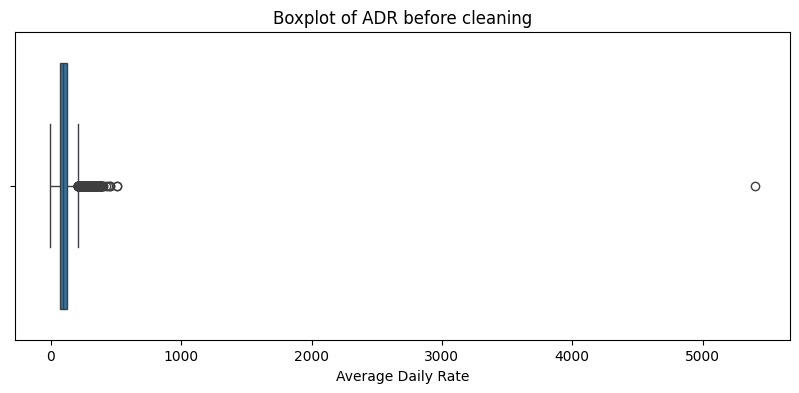

In [16]:
z_scores = stats.zscore(df["adr"])
threshold = 3
outliers = df[abs(z_scores) > threshold]
print("ADR values with |z-score| > 3:", len(outliers))
print("Smallest and largest of these:", outliers["adr"].min(), "and", outliers["adr"].max())

plt.figure(figsize=(10, 4))
sns.boxplot(x="adr", data=df)
plt.title("Boxplot of ADR before cleaning")
plt.xlabel("Average Daily Rate")
plt.show()